# 03 · Fase 3 — Segmentación de clientes (modelo M0)

**Prueba Técnica Data Scientist · Ferreycorp** — Modelo de Propensión de Compra

Fase 3 de [`docs/brief-metodologia.md`](../docs/brief-metodologia.md): *K-Means sobre las
variables demográficas, con estandarización previa y selección de k por método del codo y
silhouette; PCA para visualización e interpretación. Cada segmento recibe un nombre de negocio
y un perfil de comportamiento de compra.*

En el brief de problema, M0 entrega `segmento_i` con **dos funciones distintas**: feature del
modelo supervisado y, sobre todo, **unidad de acción comercial** — las campañas se diseñan por
segmento, no por cliente.

Tres reglas de diseño, cada una respondiendo a una forma concreta en que esta fase puede salir
mal:

| Riesgo | Regla |
|---|---|
| Agrupar por comportamiento y luego "descubrir" que los grupos se comportan distinto | El comportamiento **queda fuera** de la matriz de clustering; el perfil se construye después, con dato que el modelo no vio |
| K-Means siempre devuelve *k* grupos, haya o no estructura | `k` se elige por codo y silhouette **y** la partición se prueba por reproducibilidad (ARI sobre remuestreos) |
| Las etiquetas de K-Means son arbitrarias y cambian con la semilla | Los clusters se reordenan por ingreso medio y el mapa completo se **congela** con huella digital |

La lógica vive en [`src/ferreyros/segmentation.py`](../src/ferreyros/segmentation.py); aquí se
orquesta y se interpreta.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from ferreyros import config as cfg, data, framing, plots, preprocess
from ferreyros import segmentation as m0

plots.set_style()
pd.set_option("display.max_columns", 40, "display.width", 200)

df = data.add_paid_price_and_spend(data.load_raw())
print(f"dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")

dataset: 58,693 filas x 26 columnas


### Antes de modelar: el encuadre de la Fase 0 sigue mandando

La Fase 0 congeló la unidad de análisis, los targets, las features admisibles y el split. Toda
fase posterior arranca verificándolo, para que una deriva aparezca como una verificación fallada
y no como un número raro tres notebooks después.

In [2]:
ver_encuadre = framing.verify_frozen(df)
display(ver_encuadre)
assert ver_encuadre.attrs["coincide"], "El dataset ya no coincide con el encuadre congelado"

,verificacion,congelado,actual,estado
0,frontera del split,550,550,OK
1,filas totales,58693,58693,OK
2,clientes,500,500,OK
3,fingerprint train,47959243b182b9af,47959243b182b9af,OK
4,fingerprint test,842f57dd85e58abc,842f57dd85e58abc,OK


---
## 1 · La matriz de M0

M0 opera sobre los **500 clientes**, no sobre las 58,693 visitas: la demografía es estática por
cliente (control D2), así que una fila por visita repetiría 117 veces la misma información y
pesaría a los clientes por su número de visitas.

`ocupacion` entra como **indicadores**, no como número: 0, 1 y 2 son tres etiquetas, y tratarlas
como una escala afirmaría que 2 está al doble de distancia de 0 que 1. `nivel_educacion` sí
conserva su columna ordinal, porque ahí el orden es información.

In [3]:
M = m0.client_matrix(df)
display(M.head())
print("matriz cruda:", M.shape)

,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion_0,ocupacion_1,ocupacion_2
id,,,,,,,,
200000001,0.0,0.0,47.0,1.0,110866.0,0.0,1.0,0.0
200000002,1.0,1.0,52.0,2.0,159052.0,0.0,0.0,1.0
200000003,0.0,0.0,28.0,0.0,113212.0,0.0,1.0,0.0
200000004,0.0,0.0,37.0,1.0,119602.0,1.0,0.0,0.0
200000005,0.0,0.0,49.0,1.0,121466.0,0.0,1.0,0.0


matriz cruda: (500, 8)


In [4]:
diseno = m0.verify_design(df)
display(diseno)
print(diseno.attrs["lectura"])
assert diseno.attrs["apto"], "La matriz de M0 no es admisible"

,verificacion,esperado,obtenido,ok
0,una fila por cliente,500 clientes,500 filas,True
1,matriz de train identica a la del frame completo,identica (la demografia no cambia en el tiempo),identica,True
2,demografia invariante por cliente (D2),0 clientes con mas de un valor,0 clientes,True
3,ninguna columna de resultado ni de comportamie...,ninguna,ninguna,True
4,sin nulos,0,0,True


La matriz de M0 tiene 500 clientes x 8 columnas y pasa las cinco verificaciones. La identidad entre la matriz de train y la del frame completo es lo que prueba que los segmentos no pueden arrastrar informacion de test: la demografia es estatica por cliente.


**Consecuencia:** las cinco verificaciones pasan. La segunda es la que tiene filo: la matriz
construida **solo con el periodo de train** es idéntica a la del frame completo, así que los
segmentos no pueden arrastrar información de test. No es una declaración de buena intención —
es una comparación numérica.

Y la cuarta cierra la regla de diseño: ninguna columna de resultado ni de comportamiento está en
la matriz. El comportamiento se usa después, para **evaluar** los segmentos (§6), que es lo que
vuelve esa evaluación evidencia y no una tautología.

---
## 2 · Selección de k

El brief pide los dos criterios: codo y silhouette. Conviene adelantar que **no van a coincidir**,
y que eso es lo normal en demografía mixta: la silhouette premia particiones cada vez más finas
sobre un espacio continuo.

,k,inercia,silhouette,davies_bouldin,calinski_harabasz,delta_inercia,pct_inercia_explicada
0,2,2981.42,0.2787,1.4992,170.1,NaN,0.0
1,3,2188.60,0.3534,1.2277,205.7,792.82,26.6
2,4,1819.16,0.3403,1.1222,198.2,369.44,39.0
3,5,1601.93,0.3364,1.0965,185.3,217.23,46.3
4,6,1407.62,0.3498,1.1574,182.0,194.31,52.8
5,7,1262.49,0.3524,1.2155,178.2,145.13,57.7
6,8,1123.36,0.3747,1.1599,180.0,139.13,62.3
7,9,1040.85,0.3820,1.1391,174.5,82.51,65.1
8,10,979.42,0.3775,1.0364,167.9,61.43,67.1


El codo cae en k=3 y la silhouette maxima en k=9 (valor 0.3820); Davies-Bouldin prefiere k=10. Los dos criterios del brief no coinciden. La regla declarada rompe el empate: entre los k cuya silhouette queda a menos de 0.03 del maximo, el mas pequenio -> k=3. Una silhouette de 0.38 sobre demografia mixta indica grupos razonablemente separados, asi que el valor de la particion se prueba con la estabilidad y con el comportamiento, no con la metrica de cohesion.


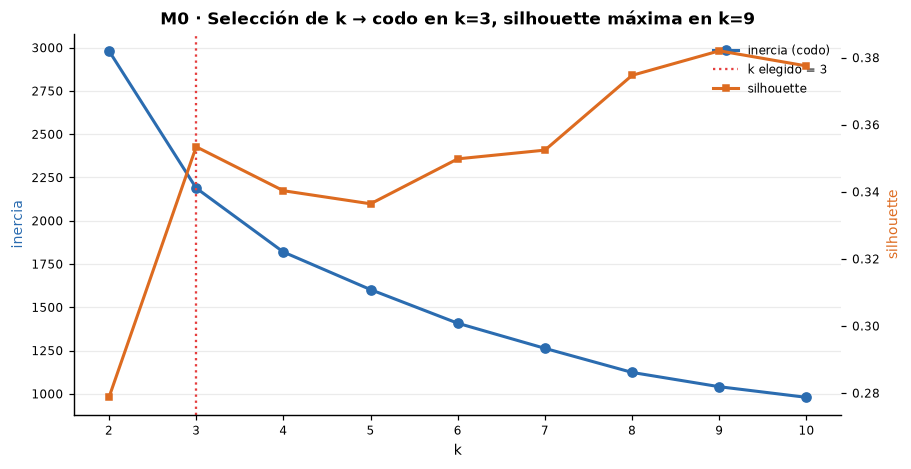

In [5]:
seleccion = m0.select_k(df)
display(seleccion)
print(seleccion.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_k_selection(seleccion, ax=ax)
plt.show()

El codo está en **k=3** (la inercia cae 793 puntos de k=2 a k=3 y solo 369 de k=3 a k=4) y la
silhouette máxima en **k=9** (0.3820, frente a 0.3534 en k=3). La regla declarada rompe el
empate: *entre los k cuya silhouette queda a menos de 0.03 del máximo, el más pequeño*. Esa
regla está escrita en el código antes de ver los segmentos, no elegida después.

Pero la razón de fondo para no irse a k=9 es otra, y es medible.

In [6]:
escaneo = m0.stability_scan(df, ks=(2, 3, 4, 9), n_repeats=20)
display(escaneo)
print(escaneo.attrs["lectura"])

,k,ari_medio,ari_min,ari_std,estable
0,2,1.0000,1.0000,0.0000,True
1,3,1.0000,1.0000,0.0000,True
2,4,0.9809,0.8990,0.0383,True
3,9,0.7866,0.5606,0.0945,True


El ARI medio cae al crecer k: k=2: 1.0000, k=3: 1.0000, k=4: 0.9809, k=9: 0.7866. Varios k empatan en el tope (k=2, k=3). La particion mas fina que sigue siendo perfectamente reproducible es k=3, y apunta en la misma direccion que el codo -- no en la de la silhouette.


**Consecuencia:** la reproducibilidad decide. Con k=3 el ARI medio es **1.0000** sobre 20
remuestreos al 80% — los mismos clientes vuelven a caer juntos, siempre. Con k=9 cae a **0.78
con un mínimo de 0.56**: a esa granularidad los grupos se recomponen al cambiar la muestra, y un
segmento que cambia de integrantes según la muestra no sirve para planificar una campaña.

Dos criterios (codo, estabilidad) contra uno (silhouette), y el que queda solo mide cohesión
geométrica, que no es el uso que se le va a dar. **k = 3.**

In [7]:
estabilidad = m0.stability(df, k=3, n_repeats=20)
display(estabilidad.head())
print(estabilidad.attrs["lectura"])
assert estabilidad.attrs["estable"], "La partición elegida no es reproducible"

,repeticion,clientes,ari
0,1,400,1.0
1,2,400,1.0
2,3,400,1.0
3,4,400,1.0
4,5,400,1.0


ARI medio 1.0000 (minimo 1.0000, desvio 0.0000) sobre 20 remuestreos al 80%. La particion es reproducible: los mismos clientes vuelven a caer juntos, asi que el segmento es una etiqueta estable sobre la que se puede planificar.


---
## 3 · Cuánto depende el resultado de cómo codificamos la ocupación

Una pregunta incómoda que conviene hacerse antes de que la haga el evaluador: `ocupacion`
one-hot aporta **3 de las 8 dimensiones** de la matriz. ¿Los segmentos salen de los datos o del
peso que le dimos a esa variable?

La forma honesta de resolverlo es reajustar el modelo con las alternativas y compararlas en lo
que importa — cohesión, reproducibilidad y separación de comportamiento — en lugar de defender
la decisión por defecto.

In [8]:
sensibilidad = m0.encoding_sensitivity(df, k=3)
display(sensibilidad)
print(sensibilidad.attrs["lectura"])

,variante,columnas,silhouette,ari_vs_elegida,amplitud_tasa_compra,tamanio_min_pct
0,one-hot (elegida),8,0.3534,1.0000,0.0795,13.6
1,ordinal,6,0.2702,0.0476,0.0758,21.4
2,sin ocupacion,5,0.3316,0.0273,0.0655,21.4


La codificacion decide los segmentos: el ARI de la variante mas alejada contra la elegida es 0.0273, es decir, particiones practicamente sin relacion. Por eso la eleccion se justifica con numeros y no con preferencia: la variante one-hot da la silhouette mas alta (0.3534) y la mayor separacion de comportamiento (0.0795). Gana en los dos criterios, asi que se conserva.


**Consecuencia — y es un hallazgo que hay que declarar, no esconder:** la codificación **decide**
los segmentos. El ARI entre la partición elegida y la de *sin ocupación* es **0.0273**: son
particiones prácticamente sin relación entre sí. No hay una segmentación "natural" esperando a
ser descubierta; hay varias, y la elección es del modelador.

Por eso la decisión se justifica con números: la variante one-hot gana en las **dos** cosas que
le vamos a pedir al segmento — la silhouette más alta (0.3534 vs 0.3316 y 0.2702) y la mayor
separación de comportamiento (amplitud de tasa 0.0795 vs 0.0655 y 0.0758). Gana en ambas, así
que se conserva; si hubiera ganado en una sola, lo correcto sería dejarlo escrito como supuesto.

---
## 4 · El modelo y sus segmentos

In [9]:
modelo = m0.fit(df, k=3)
print(f"k={modelo.k}  |  semilla={modelo.random_state}  |  silhouette={modelo.silhouette}")
print(f"columnas: {list(modelo.columnas)}")
display(modelo.tabla_nombres)

k=3  |  semilla=42  |  silhouette=0.3534
columnas: ['genero', 'estado_civil', 'edad', 'nivel_educacion', 'ingreso_anual', 'ocupacion_0', 'ocupacion_1', 'ocupacion_2']


,segmento,nombre
0,1,Dependiente · ingreso bajo
1,2,Independiente · ingreso medio
2,3,Otra ocupacion · ingreso alto


In [10]:
perfil = m0.segment_profile(modelo, df)
display(perfil)
print(perfil.attrs["lectura"])

,segmento,clientes,edad_media,ingreso_medio,educacion_media,pct_genero_1,pct_casado,pct_ocupacion_0,pct_ocupacion_1,pct_ocupacion_2,pct_clientes
0,1,184,36.5,90914.0,0.97,41.8,33.7,100.0,0.0,0.0,36.8
1,2,248,38.9,127190.0,1.10,39.9,41.1,0.0,100.0,0.0,49.6
2,3,68,43.8,183660.0,1.40,26.5,47.1,0.0,0.0,100.0,13.6


Los 3 segmentos van de 90,914 a 183,660 de ingreso medio y de 36.5 a 43.8 anios de edad media. El tamanio va del 13.6% al 49.6% de los clientes.


**Consecuencia — el modelo encontró la ocupación.** Cada segmento es **100%** un nivel de
`ocupacion`, y las demás variables se ordenan detrás:

| Segmento | Nombre | Clientes | Ingreso medio | Edad media | Educación media |
|---|---|---|---|---|---|
| 1 | Dependiente · ingreso bajo | 184 (36.8%) | 90,914 | 36.5 | 0.97 |
| 2 | Independiente · ingreso medio | 248 (49.6%) | 127,190 | 38.9 | 1.10 |
| 3 | Otra ocupación · ingreso alto | 68 (13.6%) | 183,660 | 43.8 | 1.40 |

El nombre sale del **centroide por regla fija**, no de la prosa: cuando un segmento es ≥80% una
ocupación, esa es la característica que lo define y la que lo nombra; el nivel de ingreso se lee
contra los terciles de los propios centroides, así que "alto" significa *alto en esta cartera* y
no contra un benchmark externo que nadie declaró. Volver a correr la fase no puede renombrar un
segmento en silencio.

Ocupación, ingreso, edad y educación crecen juntos — lo que el clustering separó es un **eje
socioeconómico**, y la ocupación es su marcador más limpio.

---
## 5 · PCA: ver e interpretar

El brief pide PCA para visualización e interpretación de componentes. Se usa para **ver**, nunca
para ajustar: K-Means corrió sobre el espacio estandarizado completo.

Las 2 primeras componentes explican el 52.7% de la varianza (pc1: 31.5%, pc2: 21.2%). Con demografia mixta y poco correlacionada eso es lo esperable, y es la razon de que la nube se vea continua: los segmentos son cortes de un espacio continuo, no islas.


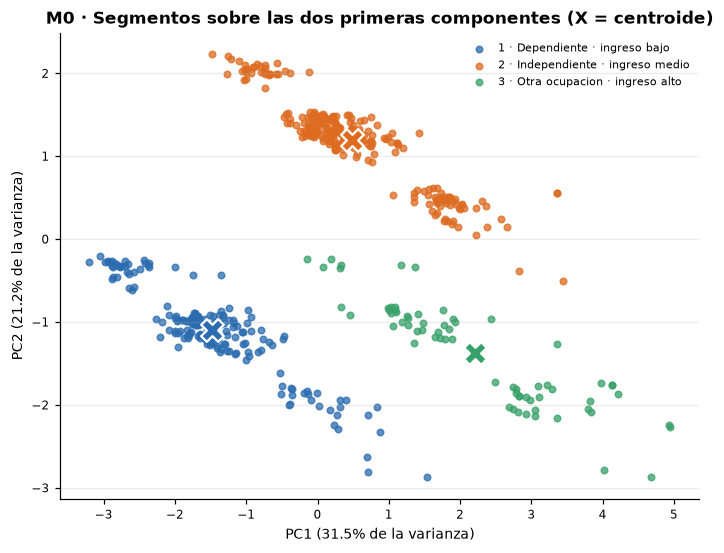

In [11]:
proyeccion = m0.pca_projection(modelo, df)
print(proyeccion.attrs["lectura"])

fig, ax = plt.subplots(figsize=(7.5, 5.5))
plots.plot_pca_segments(proyeccion, ax=ax)
plt.show()

In [12]:
m0.pca_loadings(proyeccion)

,pc1,pc2,interpretacion_dominante
genero,0.008,-0.087,pc2
estado_civil,0.159,-0.118,pc1
edad,0.393,-0.231,pc1
nivel_educacion,0.429,-0.297,pc1
ingreso_anual,0.528,-0.012,pc1
ocupacion_0,-0.447,-0.496,pc2
ocupacion_1,0.192,0.699,pc2
ocupacion_2,0.348,-0.321,pc1


**Consecuencia:** las dos primeras componentes explican el **52.7%** de la varianza (PC1 31.5%,
PC2 21.2%). Las cargas las vuelven interpretables:

- **PC1 = nivel socioeconómico**: ingreso (0.53), educación (0.43), edad (0.39) con signo
  positivo, y `ocupacion_0` con −0.45.
- **PC2 = ocupación independiente** (`ocupacion_1`, 0.70) contra el resto.

Que la nube se vea **continua** y no en islas no es un defecto del modelo: es la propiedad real
de este dato, y es coherente con el hallazgo D3 del EDA. Los segmentos son **cortes útiles de un
espacio continuo**, no tipos de cliente descubiertos. Esa distinción es la que decide cómo se usa
el segmento más abajo.

---
## 6 · Qué vale el segmento

Aquí el segmento se enfrenta a dato que **no entró** en su construcción. Tres preguntas, cada
una con un destinatario distinto en el problema de optimización.

### 6.1 · ¿Separa comportamiento de compra?

,segmento,clientes,visitas,compras,tasa_compra,unidades,ingreso,error_estandar,ic95_inf,ic95_sup,ticket_medio,pct_ingreso,nombre
0,1,184,21032,4246,0.2019,12270,22001.29,0.0028,0.1965,0.2073,5.18,26.59,Dependiente · ingreso bajo
1,2,248,29882,8408,0.2814,22659,48032.21,0.0026,0.2763,0.2865,5.71,58.04,Independiente · ingreso medio
2,3,68,7779,1984,0.2550,5685,12723.08,0.0049,0.2454,0.2647,6.41,15.37,Otra ocupacion · ingreso alto


La tasa de compra va de 0.2019 (segmento 1) a 0.2814 (segmento 2): amplitud 0.0795. Los intervalos al 95% no se solapan entre los extremos, asi que el segmento si separa comportamiento. Para comparar: entre clientes individuales la amplitud es 0.876, y eso es lo que mide D3 al concluir que la demografia segmenta pero no predice.


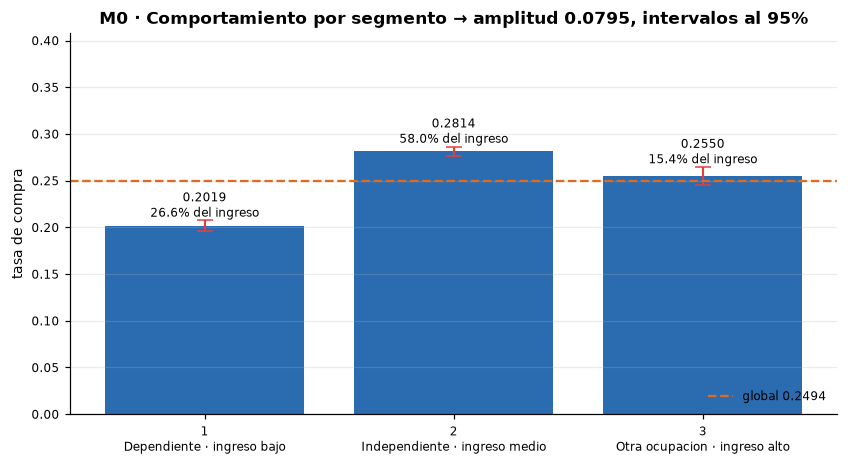

In [13]:
comportamiento = m0.segment_behaviour(modelo, df)
display(comportamiento)
print(comportamiento.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_segment_behaviour(comportamiento, float(df[cfg.TARGET_INCIDENCE].mean()), ax=ax)
plt.show()

**Consecuencia:** sí, pero con una magnitud que hay que decir en voz alta. La tasa de compra va
de **0.2019** (segmento 1) a **0.2814** (segmento 2) — amplitud **0.0795**, con intervalos al 95%
que **no se solapan**. Es separación real y estadísticamente sólida.

Y al mismo tiempo es **modesta**: entre clientes individuales la amplitud es 0.876, once veces
mayor. Esto confirma D3 del EDA en lugar de contradecirlo: *la demografía segmenta pero no
predice*. El segmento no va a ser el driver de M1; su valor está en lo que viene.

Lo que sí es inmediatamente operativo es la economía de cada segmento:

| Segmento | Clientes | Tasa | Ticket medio | % del ingreso |
|---|---|---|---|---|
| 1 · Dependiente | 36.8% | 0.2019 | 5.18 | 26.6% |
| 2 · Independiente | 49.6% | 0.2814 | 5.71 | **58.0%** |
| 3 · Otra ocupación | 13.6% | 0.2550 | **6.41** | 15.4% |

El segmento 2 es el motor: la mitad de los clientes, la tasa más alta y **58% del ingreso**. El
3 es el de mayor ticket con 68 clientes. El 1 es un tercio de la cartera con la tasa más baja —
y es donde el costo de contacto de P1 es más difícil de justificar.

### 6.2 · ¿Prefieren marcas distintas? (destinatario: P3, pricing)

,segmento,marca_1,marca_2,marca_3,marca_4,marca_5,desvio_marca_1,desvio_marca_2,desvio_marca_3,desvio_marca_4,desvio_marca_5,nombre
0,1,14.0,54.6,7.9,10.6,12.9,4.8,23.6,2.2,-9.4,-21.1,Dependiente · ingreso bajo
1,2,7.7,23.6,5.1,20.0,43.5,-1.5,-7.4,-0.6,0.0,9.5,Independiente · ingreso medio
2,3,5.2,12.3,3.6,40.0,38.9,-4.0,-18.7,-2.1,20.0,4.9,Otra ocupacion · ingreso alto


El mayor desvio frente al share global es de 23.6 puntos (marca_2 en el segmento 1). Hay preferencia de marca diferenciada: P3 puede diferenciar precio por segmento.


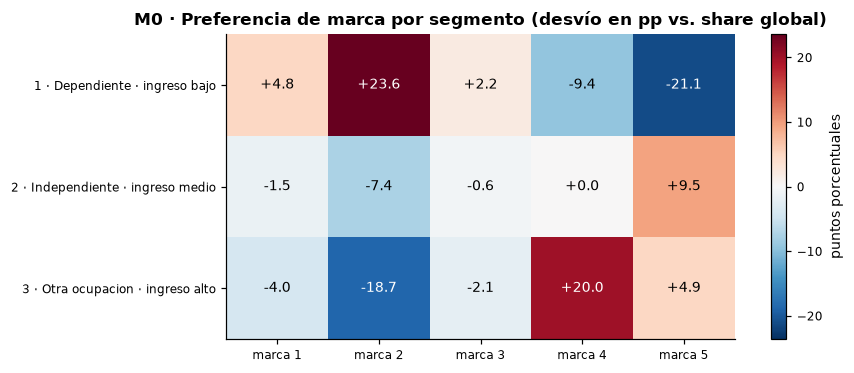

In [14]:
marcas = m0.segment_brand_share(modelo, df)
display(marcas)
print(marcas.attrs["lectura"])

fig, ax = plt.subplots(figsize=(8.5, 3.6))
plots.plot_segment_brand_share(marcas, ax=ax)
plt.show()

**Consecuencia — este es el hallazgo que justifica la fase entera.** Donde la tasa de compra
apenas separaba 8 puntos, la **preferencia de marca** separa hasta **23.6 puntos**:

| Segmento | Marca 2 | Marca 4 | Marca 5 |
|---|---|---|---|
| 1 · Dependiente · ingreso bajo | **54.6%** (+23.6) | 10.6% (−9.4) | 12.9% (**−21.1**) |
| 2 · Independiente · ingreso medio | 23.6% (−7.4) | 20.0% (0.0) | **43.5%** (+9.5) |
| 3 · Otra ocupación · ingreso alto | 12.3% (−18.7) | **40.0%** (+20.0) | 38.9% (+4.9) |

Y encaja con el arbitraje que encontró la Fase 1. La marca 5 es la de mayor efecto incremental
de promoción (+6.90 pp con 24 días), pero **a quién** se le promociona cambia todo: es el 43.5%
de las compras del segmento 2 y el 38.9% del 3, contra el 12.9% del segmento 1. Promocionar la
marca 5 al segmento 1 es gastar descuento donde casi nadie la compra.

Esto es exactamente lo que el segmento aporta al problema de optimización: `x_ijt` ya decidía a
quién contactar, y ahora P3 puede diferenciar precio y P2 puede dirigir el calendario
promocional **por segmento**, con base en el dato y no en intuición.

### 6.3 · ¿Responden a la promoción? (destinatario: P1 y P2)

,segmento,nombre,visitas_con_promo,tasa_con_promo,tasa_sin_promo,delta_pp,z,responde
0,1,Dependiente · ingreso bajo,12911,0.2233,0.1678,5.55,10.02,responde
1,2,Independiente · ingreso medio,18313,0.3004,0.2513,4.91,9.33,responde
2,3,Otra ocupacion · ingreso alto,4721,0.2722,0.2286,4.36,4.37,responde


3 de 3 segmentos mueven la incidencia con promocion por encima del ruido; el efecto va de +4.36 a +5.55 puntos. P2 tiene con esto a quien dirigir el calendario promocional.


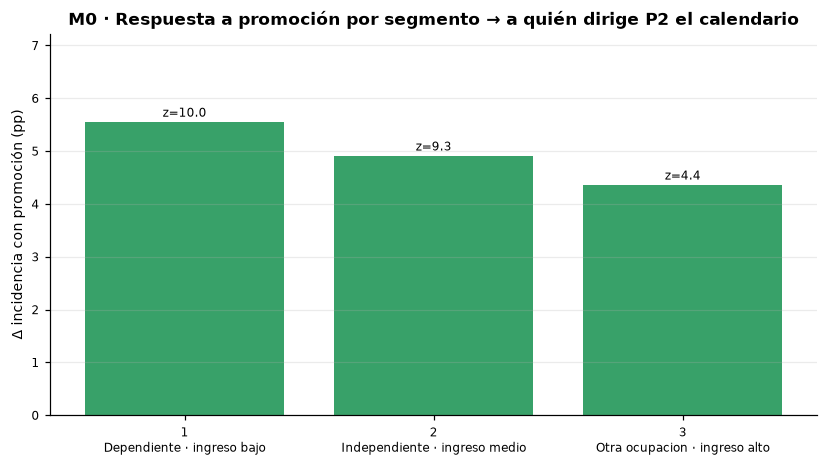

In [15]:
respuesta = m0.segment_promo_response(modelo, df)
display(respuesta)
print(respuesta.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_segment_promo_response(respuesta, ax=ax)
plt.show()

**Consecuencia:** los **tres** segmentos responden por encima del ruido, entre **+4.36 y +5.55
puntos** de incidencia. El que más responde es el segmento 1 (+5.55 pp, z=10.0) — justo el de
tasa base más baja y menor ingreso por cliente.

Ahí hay una tensión que P1 y P2 tienen que resolver explícitamente y que ningún clasificador
resuelve solo: el segmento más sensible al descuento es el menos rentable por compra. Con el
costo de contacto y el margen como parámetros, el optimizador decide; sin ellos, lo único honesto
es dejar la tensión declarada.

---
## 7 · El segmento como feature del modelo supervisado

La segunda función que el brief le pide a M0. La integración es deliberadamente de una línea:
`segmento` está declarado como columna **nominal** en `preprocess`, así que basta adjuntarlo
para que el preprocesador lo codifique one-hot — y mientras no se adjunte, todas las fases
anteriores siguen corriendo exactamente igual.

In [16]:
sin_segmento = preprocess.prepare()
con_segmento = m0.prepare_with_segment(modelo, df)

print("sin segmento:", sin_segmento.X_train.shape, "→", len(sin_segmento.feature_names), "columnas de salida")
print("con segmento:", con_segmento.X_train.shape, "→", len(con_segmento.feature_names), "columnas de salida")
print("columnas nuevas:", [n for n in con_segmento.feature_names if n not in sin_segmento.feature_names])

sin segmento: (45497, 60) → 83 columnas de salida
con segmento: (45497, 61) → 86 columnas de salida
columnas nuevas: ['segmento_1', 'segmento_2', 'segmento_3']


In [17]:
# El encuadre de la Fase 0 y el control E10 de la Fase 2 siguen cumpliéndose con la feature nueva
obedece = framing.verify_prepared_against_contract(con_segmento)
display(obedece)
assert obedece.attrs["obedece_contrato"], "La matriz con segmento no respeta el encuadre"

e10 = preprocess.verify_train_only_fit(con_segmento)
assert e10.attrs["e10_ok"], "El ajuste dejó de ser solo sobre train"
print(e10.attrs["lectura"])

,verificacion,congelado,actual,estado
0,frontera del split,550,550,OK
1,filas de train,45497,45497,OK
2,filas de test,13196,13196,OK
3,tasa de compra en train,0.2498,0.2498,OK
4,tasa de compra en test,0.248,0.248,OK
5,clientes presentes en ambos lados,500,500,OK
6,ninguna columna prohibida en la matriz,7 prohibidas,ninguna,OK


Pipeline ajustado sobre 45,497 filas de train (dias 1-550); 48 parametros cambiarian si se ajustara sobre las 58,693 filas, de modo que el limite del ajuste es material y no declarativo.


**Consecuencia:** 60 → 61 columnas de entrada y 83 → 86 de salida (las tres indicadoras del
segmento). Las siete verificaciones del encuadre siguen en OK y el control **E10** sigue probado:
añadir la feature no abrió ninguna puerta a test.

Que `feature_matrix` sea una **lista blanca** es lo que hace esto seguro: `segmento` tuvo que
declararse explícitamente como `extra`, así que ninguna columna que nadie autorizó puede llegar
al modelo por descuido.

---
## 8 · Congelar la segmentación

Las etiquetas de K-Means dependen de la semilla. Si *segmento 3* no significa lo mismo en la
Fase 4 que aquí, todo lo que se construya encima es ruido. Se congela igual que el split: con
huella digital.

In [18]:
payload = m0.freeze(modelo, df, estabilidad)
print("congelado en:", m0.SEGMENTS_PATH.relative_to(ROOT))
print(json.dumps({k: v for k, v in payload.items() if k != "asignacion"}, indent=2, ensure_ascii=False))

congelado en: artifacts/segmentos.json
{
  "fecha_ajuste": "2026-11-19",
  "k": 3,
  "random_state": 42,
  "columnas": [
    "genero",
    "estado_civil",
    "edad",
    "nivel_educacion",
    "ingreso_anual",
    "ocupacion_0",
    "ocupacion_1",
    "ocupacion_2"
  ],
  "orden_etiquetas": "ascendente por ingreso medio del centroide",
  "silhouette": 0.3534,
  "estabilidad_ari_medio": 1.0,
  "nombres": {
    "1": "Dependiente · ingreso bajo",
    "2": "Independiente · ingreso medio",
    "3": "Otra ocupacion · ingreso alto"
  },
  "tamanios": {
    "1": 184,
    "2": 248,
    "3": 68
  },
  "fingerprint": "c22163cf686ccf32"
}


In [19]:
ver = m0.verify_frozen(modelo)
display(ver)
print(ver.attrs["lectura"])
assert ver.attrs["coincide"], "El modelo ajustado no coincide con la segmentación congelada"

,campo,congelado,actual,coincide
0,k,3,3,True
1,random_state,42,42,True
2,columnas,8,8,True
3,fingerprint de la asignacion,c22163cf686ccf32,c22163cf686ccf32,True
4,nombres,3,3,True


La segmentacion ajustada coincide con la congelada en segmentos.json.


**Consecuencia:** `artifacts/segmentos.json` guarda `k`, la semilla, el orden de las etiquetas,
los nombres, los tamaños, la silhouette, el ARI de estabilidad y el **mapa completo de los 500
clientes** con su huella SHA-256. `verify_frozen` es lo que la Fase 4 ejecuta antes de usar
`segmento` como feature.

---
## 9 · Reporte de la Fase 3

In [20]:
reporte = m0.phase3_report(modelo, df, seleccion, estabilidad)
display(reporte)
print(reporte.attrs["lectura"])
assert reporte.attrs["fase3_completa"], "La Fase 3 tiene decisiones sin cerrar"

,decision,valor,evidencia,ok
0,k (codo + silhouette),k = 3,"codo en k=3, silhouette maxima en k=9 (valor 0...",True
1,estabilidad de la particion,ARI medio 1.0000,20 remuestreos al 80%,True
2,nombres de negocio,3 nombres unicos,derivados del centroide por regla fija,True
3,separacion de comportamiento,amplitud de tasa 0.0795,IC95 no se solapan entre los extremos,True
4,accion comercial: pricing por segmento,desvio maximo de share 23.6 pp,preferencia de marca por segmento,True
5,accion comercial: promocion por segmento,3 de 3 segmentos responden,delta de incidencia con y sin promocion,True


6 de 6 decisiones de la Fase 3 cerradas con evidencia ejecutada.


---
## 10 · Síntesis: qué entrega M0

| Decisión | Valor | Cómo se justificó |
|---|---|---|
| `k` | **3** | codo en k=3; silhouette máxima en k=9 pero ARI 0.78 vs **1.00**; regla de empate declarada |
| Codificación de `ocupacion` | one-hot | gana en silhouette **y** en separación de comportamiento frente a las dos alternativas |
| Etiquetas | ascendentes por ingreso del centroide | reproducibles entre corridas; congeladas con huella `c22163cf686ccf32` |
| Nombres | derivados del centroide | ≥80% de una ocupación ⇒ la ocupación nombra el segmento |
| Separación de comportamiento | amplitud 0.0795, IC95 sin solaparse | dato que no entró al clustering |
| Diferenciación de marca | hasta **23.6 pp** | base real para pricing y promoción por segmento |
| Respuesta a promoción | +4.36 a +5.55 pp, los 3 segmentos | destinatario del calendario de P2 |
| Como feature | 3 columnas one-hot, 83 → 86 | encuadre y E10 siguen verificados |

### Las tres conclusiones de esta fase

1. **El segmento vale por la acción comercial, no por la predicción.** Separa 8 puntos de tasa
   de compra frente a 88 entre clientes individuales: confirma D3 del EDA. Pero separa **23.6
   puntos** de preferencia de marca, y ahí sí cambia decisiones — P3 puede diferenciar precio y
   P2 puede dirigir el calendario.

2. **La segmentación es una elección, no un descubrimiento.** Cambiar la codificación de una
   variable produce particiones sin relación entre sí (ARI 0.027). Está declarado, y la variante
   elegida gana en los dos criterios que importan. Lo que no se puede afirmar es que estos sean
   "los" segmentos del negocio.

3. **La marca 5 necesita un destinatario, y ahora lo tiene.** La Fase 1 mostró que es el mayor
   arbitraje promocional (+6.90 pp con 24 días). Esta fase muestra a quién: segmentos 2 y 3,
   donde es el 43.5% y el 38.9% de las compras — no al segmento 1, donde es el 12.9%.

### Siguiente paso

**Fase 4** — los tres modelos encadenados sobre el split congelado del día 550: M1 incidencia
(PR-AUC como métrica principal, umbral derivado del costo de contacto), M2 elección de marca
(condicional a compra, de donde salen las elasticidades cruzadas) y M3 cantidad. Arranca con
`framing.verify_frozen(df)` y `m0.verify_frozen(modelo)`, y el baseline a batir sigue siendo el
lift ×2.43 del targeting histórico.